# Исследовательский анализ данных (EDA): Базовый табличный датасет Spotify (Baseline)
**Проект:** Сравнительный анализ влияния ручного и искусственного обогащения данных на качество и устойчивость обучения моделей машинного обучения  
**Задача:** Бинарная классификация музыкальных треков Spotify по популярности (`is_popular`) на основе аудио-характеристик и метаданных композиции.

### Паспорт источника базового датасета:
* **Файл датасета:** `base_spotify_2000.csv` (срез открытого датасета *Spotify Tracks Dataset*)
* **Лицензия:** Открытая лицензия (CC0 / Public Domain / CC BY 4.0)
* **Исходный объем:** 2 000 записей, 11 колонок
* **Метаданные трека (`ID_COLS`):** `track_name` (название композиции), `artists` (исполнители)
* **Числовые аудио-признаки (8 шт.):** `danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `valence`, `tempo`, `duration_ms`
* **Целевая переменная (таргет):** `is_popular`

### Целевые классы:
* **0: `not_popular` (`is_popular = 0`)** — нишевые, фоновые, архивные или малопрослушиваемые треки, не вошедшие в популярный сегмент каталога.
* **1: `popular` (`is_popular = 1`)** — востребованные коммерческие релизы и хиты с высоким уровнем вовлеченности слушателей.

В данном ноутбуке проводится разведочный анализ целостности, статистических распределений, корреляционной структуры и разделимости классов базового табличного датасета для планирования ручного сбора данных и формализации правил разметки (Codebook)

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

# Настройка графиков
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.size"] = 11
plt.rcParams["figure.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["axes.titlesize"] = 13

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from src.eda import (
    analyze_missing_and_types,
    compute_numeric_and_codebook_thresholds,
    compute_target_and_quotas,
    generate_markdown_report,
    load_and_audit,
    plot_numeric_by_class,
    plot_pca_projection,
    plot_spearman_correlation,
    plot_target_distribution,
    rank_features_for_label_studio,
)

DATA_PATH = ROOT_DIR / "data" / "raw" / "base_spotify_2000.csv"
TARGET_COL = "is_popular"
ID_COLS = ["track_name", "artists"]
OUT_DIR = ROOT_DIR / "reports" / "eda"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Dataset path: {DATA_PATH}")
print(f"Dataset file exists: {DATA_PATH.exists()}")
print(f"Reports output dir: {OUT_DIR}")

Dataset path: d:\labs\3_sem\da\spotify_songs-popularity_classification\data\raw\base_spotify_2000.csv
Dataset file exists: True
Reports output dir: d:\labs\3_sem\da\spotify_songs-popularity_classification\reports\eda


## 1. Санитарный контроль и аудит схемы данных
Выполним верификацию целостности и качества исходной таблицы `base_spotify_2000.csv`:
1. Проверим выполнение формального требования к объему базового датасета: $N_{\text{clean}} \ge 1\,000$ записей после дедубликации;
2. Проверим наличие явных (`NaN`) и скрытых строковых пропусков (`"?"`, `"-"`, `"unknown"`, `"none"`, `"n/a"`) во всех 11 столбцах;
3. Выявим полные дубликаты строк и дубликаты по вектору из 8 аудио-признаков (без учета текстовых полей `track_name` и `artists` — например, переиздания одной и той же фонограммы в разных сборниках), а также проверим отсутствие константных признаков ($N_{\text{unique}} \le 1$).

In [2]:
df, audit_info = load_and_audit(DATA_PATH, target_col=TARGET_COL, id_cols=ID_COLS)

print(f"Исходный размер таблицы: {audit_info['raw_rows']} строк × {audit_info['raw_cols']} столбцов")
print(f"Обнаружено полных дубликатов: {audit_info['full_duplicates']}, дубликатов по аудио-признакам: {audit_info['feature_duplicates']}")
print(f"Чистый размер после дедубликации: {audit_info['clean_rows']} строк (порог >= 1000 выполнен: {audit_info['passes_1000_threshold']})")
print(f"Всего ячеек с пропусками (NaN): {audit_info['missing_total_cells']}")
print(f"Константные признаки: {audit_info['constant_columns'] or 'не обнаружены'}")

display(analyze_missing_and_types(df))
df.head()

Исходный размер таблицы: 2000 строк × 11 столбцов
Обнаружено полных дубликатов: 0, дубликатов по аудио-признакам: 4
Чистый размер после дедубликации: 1996 строк (порог >= 1000 выполнен: True)
Всего ячеек с пропусками (NaN): 0
Константные признаки: не обнаружены


,dtype,missing_cnt,missing_pct,n_unique
track_name,str,0,0.0,1976
artists,str,0,0.0,1445
danceability,float64,0,0.0,681
energy,float64,0,0.0,813
loudness,float64,0,0.0,1857
speechiness,float64,0,0.0,788
acousticness,float64,0,0.0,1388
valence,float64,0,0.0,891
tempo,float64,0,0.0,1916
duration_ms,int64,0,0.0,1939


,track_name,artists,danceability,energy,loudness,speechiness,acousticness,valence,tempo,duration_ms,is_popular
0,Spiritual Value,Villem;Mcleod,0.652,0.894,-5.668,0.0544,0.000371,0.102,170.053,318938,0
1,Breaking the Habit,Linkin Park,0.579,0.849,-5.218,0.0303,0.108000,0.581,100.021,196906,1
2,"Tod dem Biest - aus ""Die Schöne und das Biest""...",Peter Edelmann;Chorus,0.499,0.515,-16.027,0.2510,0.750000,0.494,132.050,209400,0
3,Loose Change,Devin Kennedy,0.825,0.420,-14.702,0.0516,0.326000,0.781,119.953,163500,1
4,I Can't Turn Around,J.M. Silk,0.739,0.708,-9.338,0.0382,0.021600,0.822,125.916,230586,0


### Выводы по санитарному контролю:
* **Объем и дубликаты:** В исходной таблице из 2 000 записей полные дубликаты отсутствуют (`full_duplicates = 0`), однако обнаружено **4 дубликата по аудио-признакам** (`feature_duplicates = 4` — идентичные по звучанию релизы/ремастеры). После их удаления чистая выборка составляет **1 996 уникальных треков**, что почти вдвое превышает минимальный порог регламента ($\ge 1\,000$ записей).
* **Пропуски и типы данных:** Пропущенных значений (`NaN`) ни в одном из 11 столбцов нет (`missing_total_cells = 0`). Текстовые метаданные (`track_name`, `artists`) выделены в `ID_COLS` — они будут выводиться аннотаторам в карточке разметки как справочный контекст, но исключены из расчета численных порогов.

## 2. Баланс классов и расчет квот для ручного обогащения
Оценим распределение треков между классами `0` (`not_popular`) и `1` (`popular`). Это необходимо для:
* **Расчета квот ручного сбора:** определения объема новых треков, собираемых вручную (по 50–100 экземпляров на каждый класс);

Метаданные распределения классов: {'n_classes': 2, 'imbalance_ratio': 1.0, 'kappa_paradox_risk': False}


,class_label,count,share_pct,manual_quota_equal (50-100),manual_quota_proportional,pilot_50_stratified
0,1,999,50.05,75,75,25
1,0,997,49.95,75,75,25


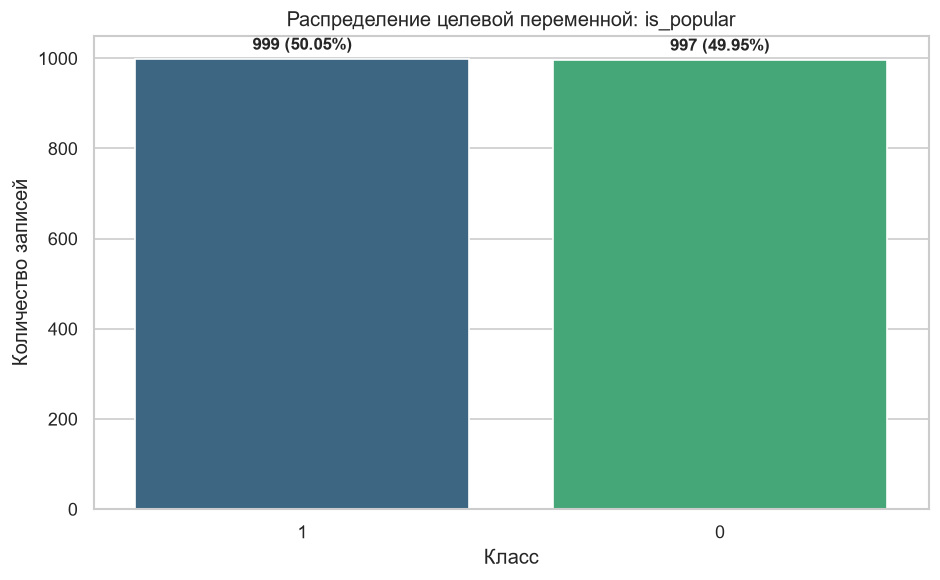

In [3]:
target_df, target_meta = compute_target_and_quotas(df, target_col=TARGET_COL, quota_per_class=75)
print("Метаданные распределения классов:", target_meta)
display(target_df)

fig_target = plot_target_distribution(
    target_df, TARGET_COL, len(df), save_path=OUT_DIR / "01_target_distribution.png"
)
plt.show()

### Выводы по балансу классов:
* **Идеальный баланс выборки:** Исходный датасет был сбалансирован 50/50 (по 1 000 треков каждого класса). После удаления 4 дубликатов по аудио-признакам соотношение сохранилось: **999 популярных треков (`50.05%`, класс `1`)** и **997 непопулярных треков (`49.95%`, класс `0`)**, коэффициент дисбаланса равен `1.0`.
* **План ручного сбора и пилотной разметки:** Поскольку оба класса представлены поровну, равная и пропорциональная квоты совпадают — целевой ориентир ручного сбора составляет **по 50–100 новых треков на каждый класс**

## 3. Оценка информативности аудио-признаков (Mutual Information)
Оценим нелинейную зависимость каждого из 8 числовых аудио-признаков с целевой меткой `is_popular` через взаимную информацию $I(X_j; Y)$. Ранжирование позволит понять, какие характеристики трека сильнее всего отличают популярные релизы от нишевых композиций, и вынести их на первые позиции в карточке разметчика **Label Studio** и правилах **Codebook**.

In [4]:
ls_ranking = rank_features_for_label_studio(df, target_col=TARGET_COL, id_cols=ID_COLS, top_k=8)
display(ls_ranking)

,feature,dtype,mi_score,n_unique,include_in_label_studio
0,duration_ms,int64,0.0644,1939,True
1,speechiness,float64,0.0351,788,True
2,acousticness,float64,0.0349,1388,True
3,energy,float64,0.0296,813,True
4,tempo,float64,0.0216,1916,True
5,danceability,float64,0.0125,681,True
6,loudness,float64,0.0036,1857,True
7,valence,float64,0.0023,891,True


### Выводы по информативности признаков:
* **Главные предикторы популярности:** Наибольшую взаимную информацию с целевым классом показывают длительность трека **`duration_ms`** (`mi_score = 0.0644`), доля речевого речитатива **`speechiness`** (`0.0351`), акустичность **`acousticness`** (`0.0349`), энергичность **`energy`** (`0.0296`) и темп **`tempo`** (`0.0216`).
* **Второстепенные признаки:** Танцевальность (`danceability`, `0.0125`), общая громкость (`loudness`, `0.0036`) и эмоциональная окраска (`valence`, `0.0023`) сами по себе слабо разделяют классы в отрыве от остальных параметров.

## 4. Статистические распределения, корреляции и поиск «серых зон» для Codebook
Проведем детальный анализ 8 аудио-характеристик для наполнения документа **Codebook**:
* **Квартили ($Q_{25}, \text{Median}, Q_{75}$) и выбросы ($1.5 \times \text{IQR}$):** зафиксируют типичные диапазоны звучания для классов `0` и `1`, а также покажут, где распределения перекрываются («серая зона»);
* **Матрица корреляций Спирмена ($\rho$):** выявит физически связанные аудио-признаки, чтобы аннотаторы не учитывали один и тот же акустический фактор дважды;
* **2D-проекция главных компонент (PCA):** покажет степень линейной неразделимости классов и необходимость четких правил разрешения пограничных случаев в Codebook.

Общие описательные статистики и доля выбросов по правилу 1.5 * IQR:


,feature,mean,std,min,q05,q25,median,q75,q95,max,iqr_outliers_cnt,iqr_outliers_pct
0,danceability,0.577,0.175,0.000,0.257,0.461,0.590,0.708,0.840,0.979,8,0.40
1,energy,0.635,0.262,0.002,0.119,0.460,0.679,0.860,0.970,1.000,0,0.00
2,loudness,-8.786,5.510,-41.531,-20.515,-10.649,-7.293,-5.190,-3.159,-0.132,117,5.86
3,speechiness,0.103,0.170,0.000,0.028,0.035,0.049,0.086,0.322,0.962,234,11.72
4,acousticness,0.300,0.340,0.000,0.000,0.010,0.119,0.580,0.962,0.996,0,0.00
5,valence,0.468,0.258,0.000,0.076,0.252,0.449,0.675,0.911,0.988,0,0.00
6,tempo,121.590,29.710,0.000,76.008,100.008,121.585,138.803,175.001,220.525,21,1.05
7,duration_ms,241256.234,176855.222,30474.000,107097.500,178104.250,219433.000,272060.500,415269.250,4730302.000,108,5.41



Пороговые квантили по классам для включения в Codebook:


,feature,class,q25 (нижняя граница нормы класса),median (типичное значение),q75 (верхняя граница нормы класса)
0,duration_ms,0,183232.000,238714.000,302586.000
1,duration_ms,1,175742.000,210240.000,247841.000
2,speechiness,0,0.038,0.055,0.103
3,speechiness,1,0.034,0.045,0.072
4,acousticness,0,0.003,0.075,0.653
5,acousticness,1,0.026,0.173,0.518
6,energy,0,0.490,0.733,0.903
7,energy,1,0.439,0.625,0.808
8,tempo,0,103.551,123.450,139.665
9,tempo,1,97.951,119.957,137.042


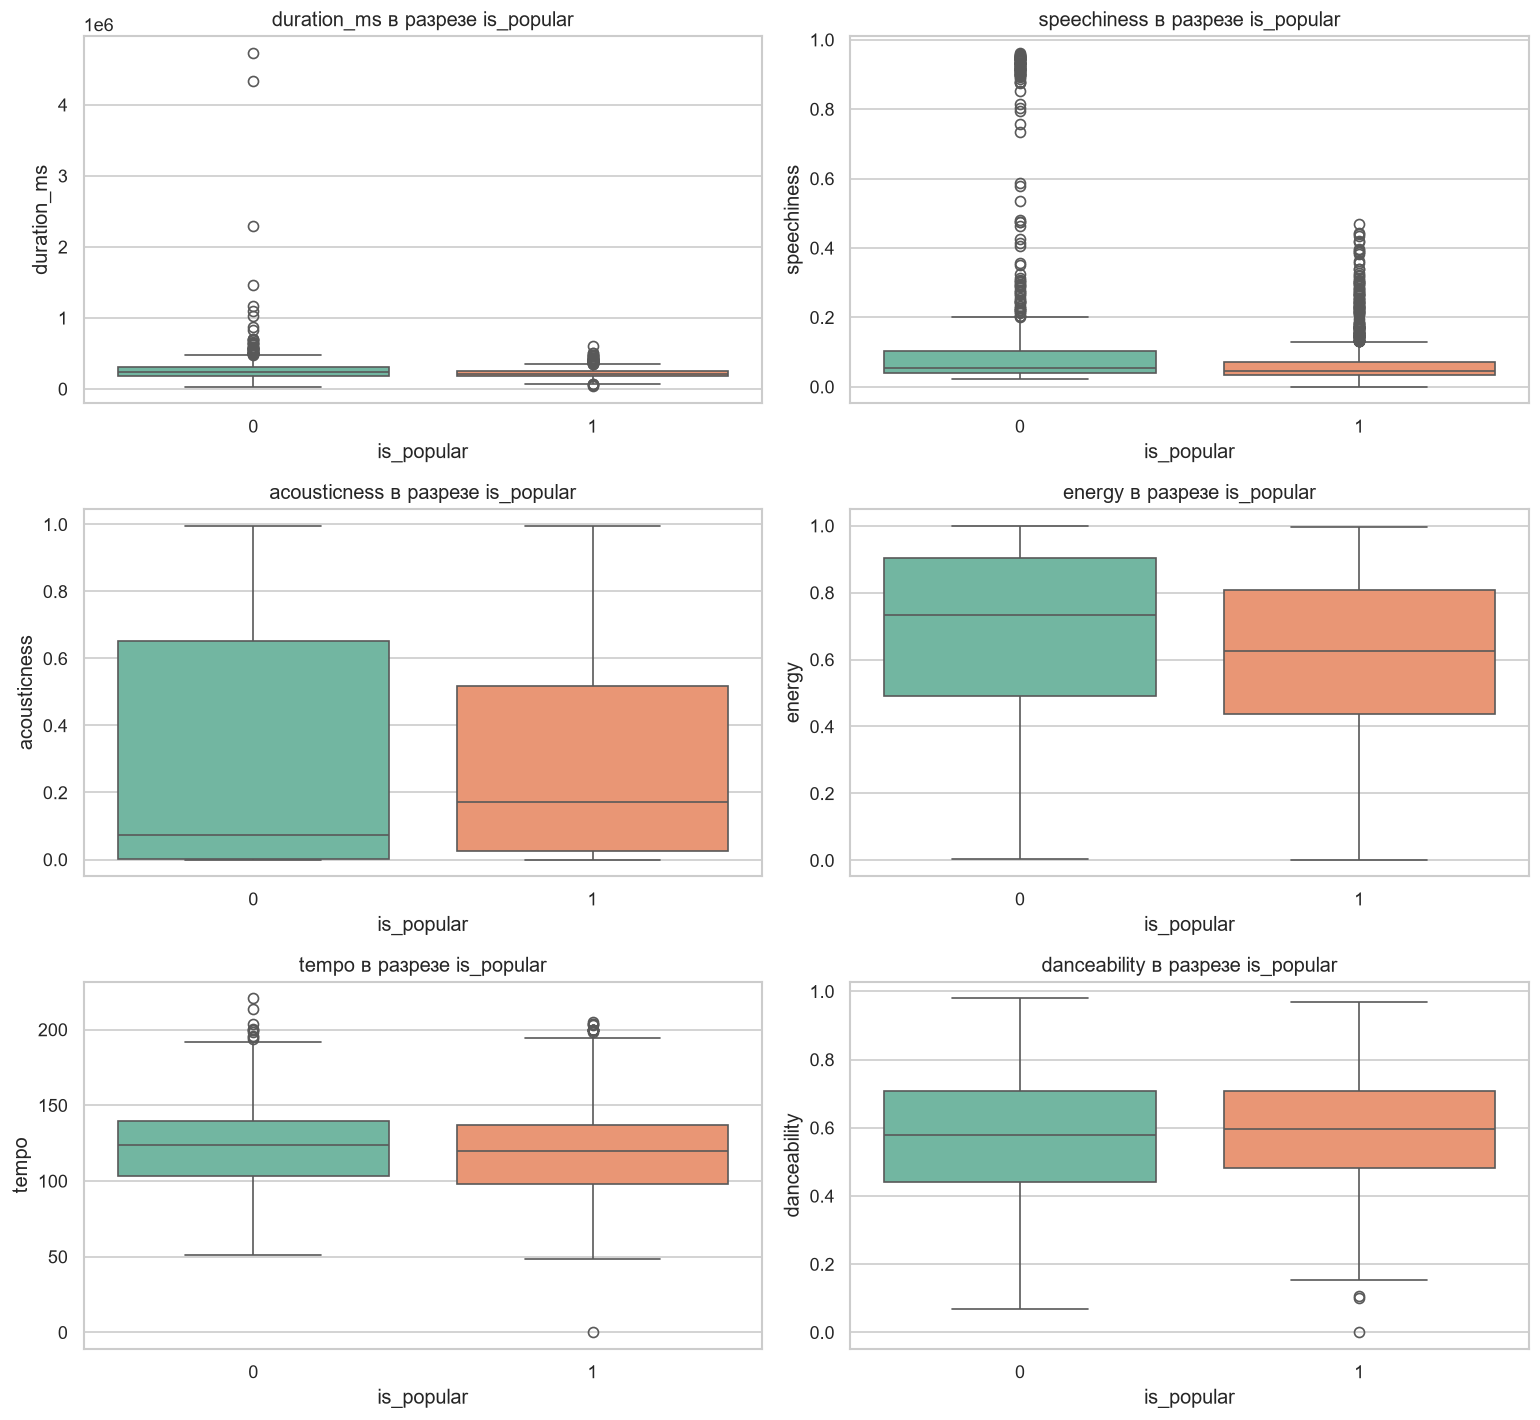

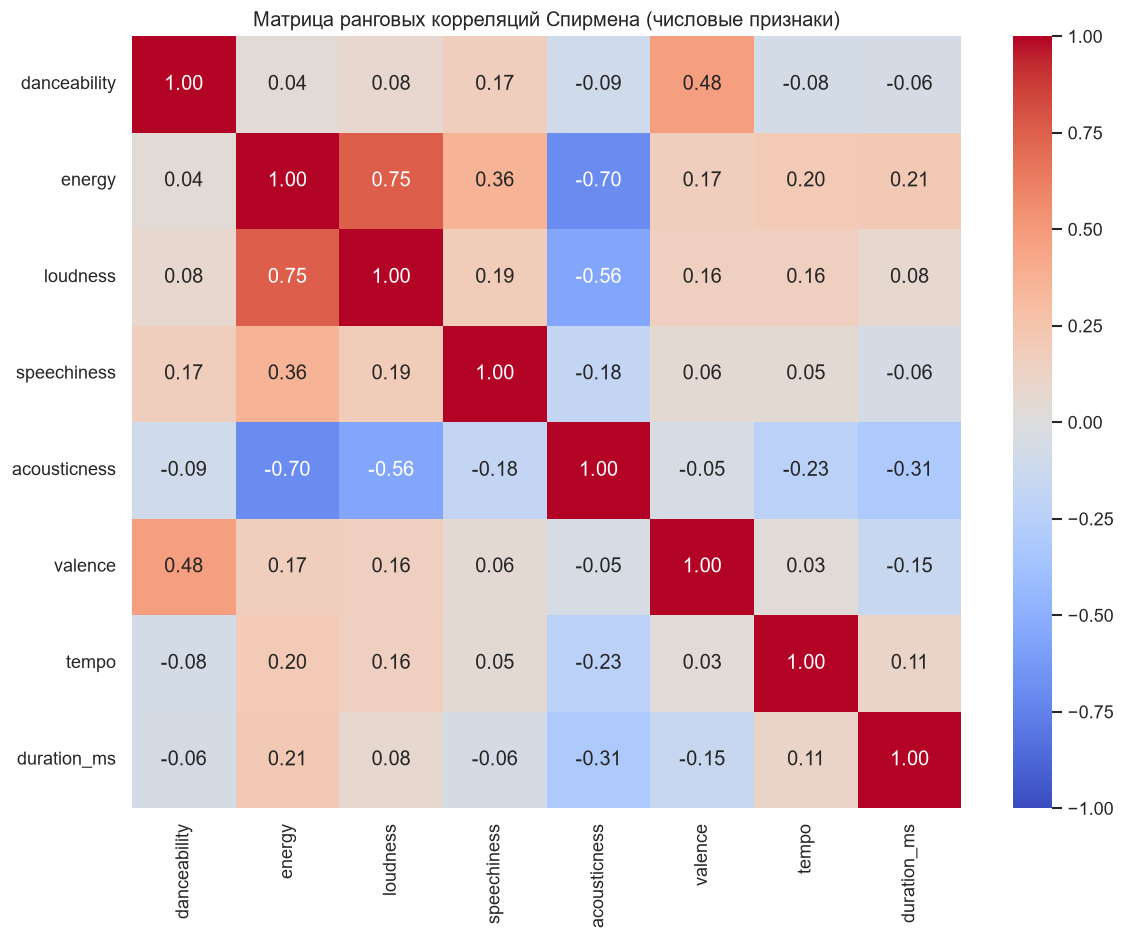

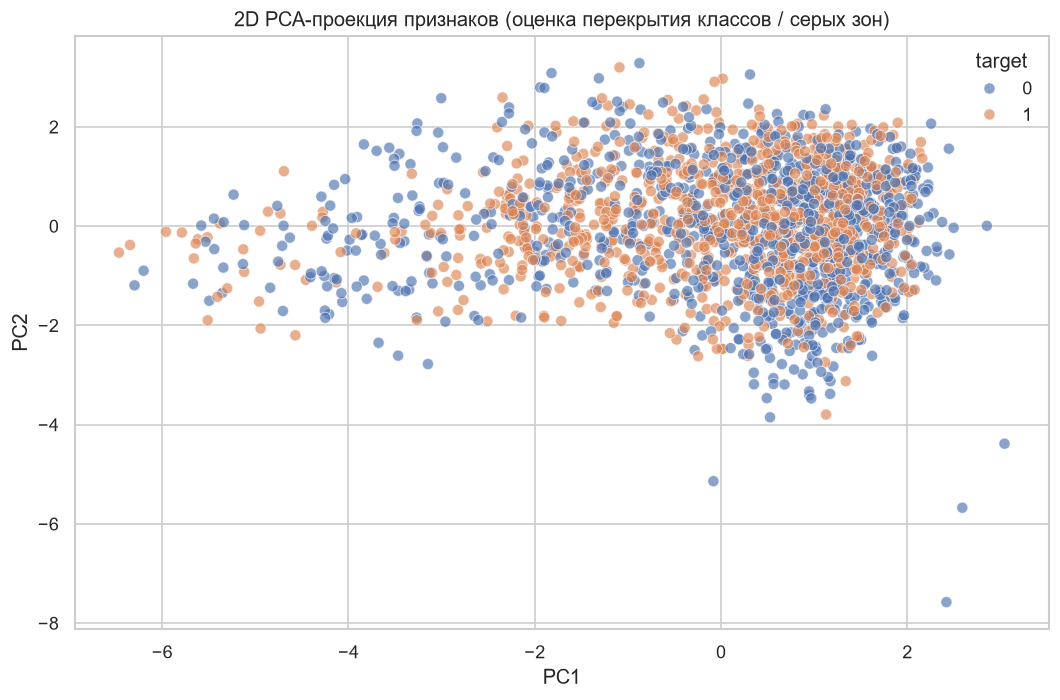

In [5]:
top_features = ls_ranking["feature"].tolist()
num_stats_df, codebook_thresholds_df = compute_numeric_and_codebook_thresholds(
    df, target_col=TARGET_COL, top_features=top_features
)

print("Общие описательные статистики и доля выбросов по правилу 1.5 * IQR:")
display(num_stats_df)

print("\nПороговые квантили по классам для включения в Codebook:")
display(codebook_thresholds_df)

fig_box = plot_numeric_by_class(df, TARGET_COL, top_features, save_path=OUT_DIR / "02_top_numeric_by_class.png")
plt.show()

fig_corr = plot_spearman_correlation(df, TARGET_COL, save_path=OUT_DIR / "03_spearman_correlation.png")
plt.show()

fig_pca = plot_pca_projection(df, TARGET_COL, ID_COLS, save_path=OUT_DIR / "04_pca_2d_projection.png")
plt.show()

### Выводы по распределениям и правила для Codebook:
1. **Характерные профили классов (ориентиры для разметки):**
   * **Длительность (`duration_ms`):** Популярные треки (`is_popular = 1`) заметно короче и укладываются в компактный радиоформат — медиана **210.2 сек** (~3.5 мин, межквартильный размах `175.7–247.8` сек). Непопулярные треки (`is_popular = 0`) в среднем длиннее (медиана **238.7 сек**, $Q_{75} = 302.6$ сек — длинные инструментальные миксы, саундтреки и классические записи).
   * **Энергичность (`energy`) и акустичность (`acousticness`):** В классе `0` много жестких клубных/метал-треков с экстремальной энергичностью (медиана `energy = 0.733`, $Q_{75} = 0.903$, медиана `acousticness = 0.075`), тогда как популярные треки (`1`) имеют более сбалансированную аранжировку (медиана `energy = 0.625`, `acousticness = 0.173`) и чуть более высокую громкость мастеринга (медиана `loudness = -6.91` дБ против `-7.60` дБ у класса `0`).
2. **Анализ выбросов:** Наибольшая доля выбросов по правилу $1.5 \times \text{IQR}$ наблюдается в признаках **`speechiness` (`11.72%`, 234 трека)** — за счет рэп-треков, скитов и аудиокниг, **`loudness` (`5.86%`, 117 треков)** — тихие эмбиент/классические записи до `-41.5` дБ, и **`duration_ms` (`5.41%`, 108 треков)** — DJ-сеты и симфонические записи длительностью до 78.8 минут (`4 730 302` мс). В **Codebook** экстремально длинные записи ($> 300\,000$ мс) и очень тихие треки ($< -14$ дБ) закрепляются как маркеры класса `0`, если исполнитель не относится к топ-чартам.
3. **Корреляции признаков:** Выявлена сильная положительная ранговая связь между **`energy` и `loudness` ($\rho = 0.75$)** и сильная отрицательная связь **`energy` и `acousticness` ($\rho = -0.70$)** (чем больше живых акустических инструментов, тем ниже плотность и громкость трека). Также умеренно коррелируют **`danceability` и `valence` ($\rho = 0.48$)** — танцевальные треки чаще звучат позитивно.
4. **Перекрытие в 2D PCA («серая зона»):** Облака классов `0` и `1` в пространстве первых двух главных компонент существенно пересекаются. Это доказывает, что при ручной разметке в **Codebook** нельзя полагаться только на один числовой порог — решение должно приниматься по комбинации аудио-профиля (стандартная длительность `175–250` сек + коммерческий мастеринг `loudness > -9` дБ + умеренная `danceability > 0.50`) и известности артиста (`artists`).

In [6]:
report_path = generate_markdown_report(
    audit_info=audit_info,
    target_df=target_df,
    target_meta=target_meta,
    ls_ranking=ls_ranking,
    codebook_thresholds_df=codebook_thresholds_df,
    output_dir=OUT_DIR,
)
display(Markdown(report_path.read_text(encoding="utf-8")))

# Итоги EDA табличного датасета (`base_spotify_2000.csv`)

## 1. Паспорт и формальные требования
- **Исходный размер:** 2000 строк × 11 столбцов
- **Полных дубликатов:** 0 | **Дубликатов по признакам:** 4
- **Чистый размер после удаления дублей:** **1996** строк (✅ Выполнено (>= 1000 записей))
- **Всего ячеек с пропусками:** 0
- **Константные колонки:** нет

## 2. Баланс классов и квоты на ручной сбор (50–100 на класс)
✅ Классы сбалансированы умеренно, риск парадокса Каппы низкий.

|   class_label |   count |   share_pct |   manual_quota_equal (50-100) |   manual_quota_proportional |   pilot_50_stratified |
|--------------:|--------:|------------:|------------------------------:|----------------------------:|----------------------:|
|             1 |     999 |       50.05 |                            75 |                          75 |                    25 |
|             0 |     997 |       49.95 |                            75 |                          75 |                    25 |

## 3. Топ информативных признаков для карточки Label Studio
Рекомендуемые колонки для отображения разметчикам (`8` шт.): `duration_ms, speechiness, acousticness, energy, tempo, danceability, loudness, valence`

| feature      | dtype   |   mi_score |   n_unique | include_in_label_studio   |
|:-------------|:--------|-----------:|-----------:|:--------------------------|
| duration_ms  | int64   |     0.0644 |       1939 | True                      |
| speechiness  | float64 |     0.0351 |        788 | True                      |
| acousticness | float64 |     0.0349 |       1388 | True                      |
| energy       | float64 |     0.0296 |        813 | True                      |
| tempo        | float64 |     0.0216 |       1916 | True                      |
| danceability | float64 |     0.0125 |        681 | True                      |
| loudness     | float64 |     0.0036 |       1857 | True                      |
| valence      | float64 |     0.0023 |        891 | True                      |

## 4. Ориентиры и «серые зоны» для Codebook (медианы и IQR по классам)
| feature      |   class |   q25 (нижняя граница нормы класса) |   median (типичное значение) |   q75 (верхняя граница нормы класса) |
|:-------------|--------:|------------------------------------:|-----------------------------:|-------------------------------------:|
| duration_ms  |       0 |                          183232     |                   238714     |                           302586     |
| duration_ms  |       1 |                          175742     |                   210240     |                           247841     |
| speechiness  |       0 |                               0.038 |                        0.055 |                                0.103 |
| speechiness  |       1 |                               0.034 |                        0.045 |                                0.072 |
| acousticness |       0 |                               0.003 |                        0.075 |                                0.653 |
| acousticness |       1 |                               0.026 |                        0.173 |                                0.518 |
| energy       |       0 |                               0.49  |                        0.733 |                                0.903 |
| energy       |       1 |                               0.439 |                        0.625 |                                0.808 |
| tempo        |       0 |                             103.551 |                      123.45  |                              139.665 |
| tempo        |       1 |                              97.951 |                      119.957 |                              137.042 |
| danceability |       0 |                               0.44  |                        0.579 |                                0.709 |
| danceability |       1 |                               0.481 |                        0.595 |                                0.707 |